## 1. Imports and Setup

In [1]:
import os
import json
import pickle
import warnings
warnings.filterwarnings("ignore")

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.manifold import TSNE

from config import (
    DATASET_DIR, FACE_MODEL_DIR,
    INSIGHTFACE_ROOT, INSIGHTFACE_NAME,
    SVM_FULL_PATH, SVM_MASK_PATH,
    LABELS_PATH, EMBED_META_PATH,
    ensure_dirs,
)
from model.mask.locator import get_mask_polygon, apply_synthetic_mask

ensure_dirs()
print("Setup complete")

Setup complete


## 2. Load InsightFace Model
Detects faces and converts each face into a 512-d embedding vector.

In [2]:
from insightface.app import FaceAnalysis

app = FaceAnalysis(name=INSIGHTFACE_NAME, root=INSIGHTFACE_ROOT, providers=["CPUExecutionProvider"])
app.prepare(ctx_id=-1, det_size=(640, 640))
print("InsightFace ready")

Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\calvi\Downloads\Project\BE_Project\BE_Project_V2\Other Models\face_recognition\models\buffalo_l\1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\calvi\Downloads\Project\BE_Project\BE_Project_V2\Other Models\face_recognition\models\buffalo_l\2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\calvi\Downloads\Project\BE_Project\BE_Project_V2\Other Models\face_recognition\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\calvi\Downloads\Project\BE_Project\BE_Project_V2\Other Models\face_recognition\models\buffalo_l\genderage.o

## 3. Helper Functions
Functions to embed full faces and synthetically masked faces.

In [3]:
def pad_image(img, margin=0.5):
    """Add border padding so faces near edges get detected."""
    m = int(max(img.shape[:2]) * margin)
    return cv2.copyMakeBorder(img, m, m, m, m, cv2.BORDER_REPLICATE)


def pick_largest_face(faces):
    """Return the face with the largest bounding box area."""
    return max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))


def embed(path):
    """Compute 512-d embedding for the largest face in an image."""
    img = cv2.imread(path)
    if img is None:
        return None
    faces = app.get(pad_image(img))
    if not faces:
        return None
    return np.asarray(pick_largest_face(faces).normed_embedding, dtype=np.float32)


def embed_masked(path):
    """Synthesize a masked face, then compute its embedding."""
    img = cv2.imread(path)
    if img is None:
        return None
    padded = pad_image(img)
    faces = app.get(padded)
    if not faces:
        return None
    face = pick_largest_face(faces)
    mask_poly = get_mask_polygon(face, padded.shape)
    masked = apply_synthetic_mask(padded, mask_poly)
    masked_faces = app.get(masked)
    if not masked_faces:
        return None
    return np.asarray(pick_largest_face(masked_faces).normed_embedding, dtype=np.float32)


print("Helpers ready")

Helpers ready


## 4. Load Dataset
Scan the dataset folder for person folders and collect all image paths.

In [4]:
persons = sorted([d for d in os.listdir(DATASET_DIR)
                  if os.path.isdir(os.path.join(DATASET_DIR, d))])
label_map = {name: idx for idx, name in enumerate(persons)}

samples = []
for person in persons:
    person_dir = os.path.join(DATASET_DIR, person)
    for filename in sorted(os.listdir(person_dir)):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            samples.append((os.path.join(person_dir, filename), label_map[person]))

print(f"Persons: {persons}")
print(f"Total images: {len(samples)}")

Persons: ['Calvin', 'Mohan', 'Ronit', 'Vedang']
Total images: 304


## 5. Compute Full-Face Embeddings
Pass each image through InsightFace to get a 512-d embedding vector.

In [5]:
embeddings, labels = [], []
for path, label in samples:
    emb = embed(path)
    if emb is None:
        print("SKIP (no face):", path)
        continue
    embeddings.append(emb)
    labels.append(label)

X = np.vstack(embeddings)
y = np.array(labels)

print(f"Embeddings: {X.shape}")
print(f"Per person: { {persons[i]: int((y == i).sum()) for i in range(len(persons))} }")

Embeddings: (304, 512)
Per person: {'Calvin': 100, 'Mohan': 89, 'Ronit': 53, 'Vedang': 62}


## 6. Train Full-Face SVM
Train an SVM classifier on unmasked face embeddings.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

svm_full = SVC(C=10.0, kernel="rbf", gamma="scale", probability=True, random_state=42)
svm_full.fit(X_train, y_train)

pred_full = svm_full.predict(X_test)
acc_full = accuracy_score(y_test, pred_full)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Full-face accuracy: {acc_full:.1%}")
print(classification_report(y_test, pred_full, target_names=persons, digits=2))

Train: (243, 512), Test: (61, 512)
Full-face accuracy: 100.0%
              precision    recall  f1-score   support

      Calvin       1.00      1.00      1.00        20
       Mohan       1.00      1.00      1.00        18
       Ronit       1.00      1.00      1.00        11
      Vedang       1.00      1.00      1.00        12

    accuracy                           1.00        61
   macro avg       1.00      1.00      1.00        61
weighted avg       1.00      1.00      1.00        61



## 7. Visualize Full-Face Results
Confusion matrix and per-class accuracy chart.

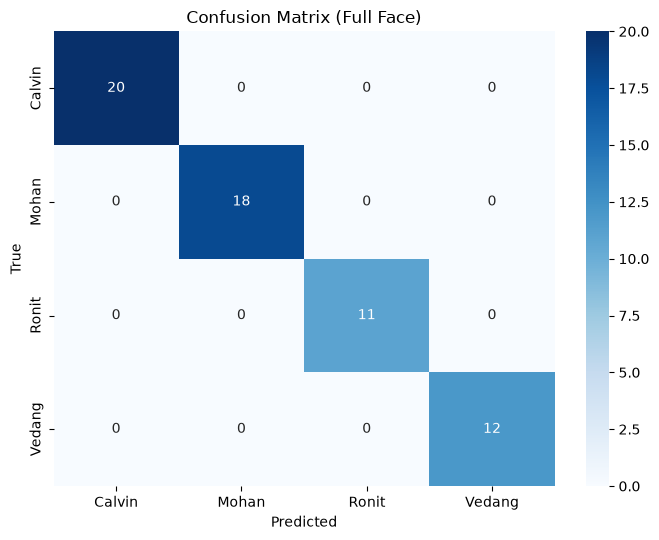

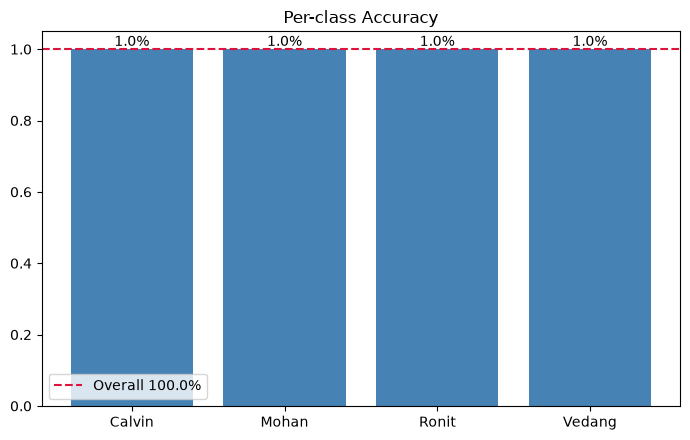

In [7]:
cm = confusion_matrix(y_test, pred_full, labels=range(len(persons)))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=persons, yticklabels=persons, ax=ax)
ax.set_title("Confusion Matrix (Full Face)")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(FACE_MODEL_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

per_class = cm.diagonal() / np.bincount(y_test, minlength=len(persons))
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(persons, per_class, color="steelblue")
ax.axhline(acc_full, color="crimson", ls="--", label=f"Overall {acc_full:.1%}")
ax.bar_label(bars, fmt="%.1f%%")
ax.set_ylim(0, 1.05)
ax.set_title("Per-class Accuracy")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FACE_MODEL_DIR, "per_class_accuracy.png"), dpi=150)
plt.show()

## 8. t-SNE (t-distributed Stochastic Neighbor Embedding technique)Visualization
Project 512-d embeddings into 2D to see how well faces cluster by person.

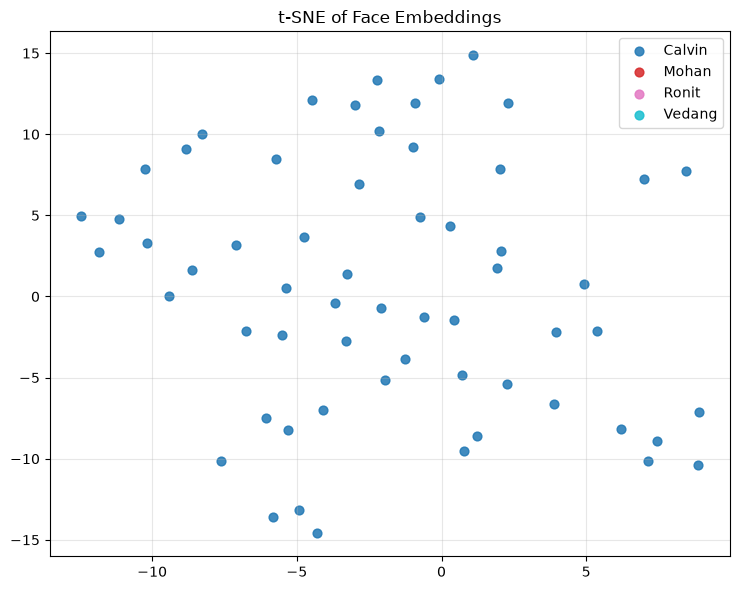

In [8]:
from sklearn.utils import resample

n_per_person = 15
tsne_idx = []
for i in range(len(persons)):
    idxs = np.where(y == i)[0]
    chosen = resample(idxs, n_samples=min(n_per_person, len(idxs)), random_state=42, replace=False)
    tsne_idx.extend(chosen)
tsne_idx = np.array(tsne_idx)

tsne = TSNE(n_components=2, perplexity=min(12, len(tsne_idx) - 1), random_state=42, init="pca")
projected = tsne.fit_transform(X[tsne_idx])
y_tsne = y[tsne_idx]

colors = plt.cm.tab10(np.linspace(0, 1, len(persons)))
fig, ax = plt.subplots(figsize=(7.5, 6))
for i in range(len(persons)):
    mask = y_tsne == i
    ax.scatter(projected[mask, 0], projected[mask, 1],
               c=[colors[i]], label=persons[i], s=40, alpha=0.85)
ax.set_title("t-SNE of Face Embeddings")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FACE_MODEL_DIR, "tsne.png"), dpi=150)
plt.show()

## 9. Compute Masked Embeddings
Synthesize masked faces (lower half covered) and compute their embeddings.

In [9]:
masked_embeddings, masked_labels = [], []
for path, label in samples:
    emb = embed_masked(path)
    if emb is None:
        continue
    masked_embeddings.append(emb)
    masked_labels.append(label)

Xm = np.vstack(masked_embeddings)
ym = np.array(masked_labels)

print(f"Masked embeddings: {Xm.shape}")

KeyboardInterrupt: 

## 10. Train Mask-Robust SVM
Train a second SVM on masked face embeddings.

In [ ]:
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    Xm, ym, test_size=0.2, stratify=ym, random_state=42
)

svm_mask = SVC(C=10.0, kernel="rbf", gamma="scale", probability=True, random_state=42)
svm_mask.fit(Xm_train, ym_train)

pred_mask = svm_mask.predict(Xm_test)
acc_mask = accuracy_score(ym_test, pred_mask)

print(f"Mask-robust accuracy: {acc_mask:.1%}")

cm_mask = confusion_matrix(ym_test, pred_mask, labels=range(len(persons)))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm_mask, annot=True, fmt="d", cmap="Greens",
            xticklabels=persons, yticklabels=persons, ax=ax)
ax.set_title("Confusion Matrix (Masked Face)")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(FACE_MODEL_DIR, "confusion_matrix_masked.png"), dpi=150)
plt.show()

## 11. Cross-Check Both Classifiers
Test each classifier on both full and masked faces to compare performance.

In [ ]:
full_on_full = accuracy_score(y_test, svm_full.predict(X_test))
full_on_mask = accuracy_score(ym_test, svm_full.predict(Xm_test))
mask_on_mask = accuracy_score(ym_test, svm_mask.predict(Xm_test))
mask_on_full = accuracy_score(y_test, svm_mask.predict(X_test))

labels_chart = ["Full on full", "Full on masked", "Mask on masked", "Mask on full"]
values = [full_on_full, full_on_mask, mask_on_mask, mask_on_full]
colors = ["steelblue", "salmon", "mediumseagreen", "gold"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(labels_chart, values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 1.05)
ax.set_title("Classifier Accuracy by View")
ax.tick_params(axis="x", rotation=12)
plt.tight_layout()
plt.savefig(os.path.join(FACE_MODEL_DIR, "masked_vs_unmasked.png"), dpi=150)
plt.show()

print(f"Full SVM on full faces:  {full_on_full:.1%}")
print(f"Full SVM on masked:      {full_on_mask:.1%}")
print(f"Mask SVM on masked:      {mask_on_mask:.1%}")
print(f"Mask SVM on full faces:  {mask_on_full:.1%}")

## 12. Save Models
Save trained SVMs, labels, and metadata to disk.

In [ ]:
with open(SVM_FULL_PATH, "wb") as fh:
    pickle.dump(svm_full, fh)
with open(SVM_MASK_PATH, "wb") as fh:
    pickle.dump(svm_mask, fh)

with open(LABELS_PATH, "w") as fh:
    json.dump({"persons": persons, "model": "insightface-buffalo_l", "img_size": 112}, fh, indent=2)

meta = {
    "embedding_dim": int(X.shape[1]),
    "n_samples_full": int(len(X)),
    "n_samples_masked": int(len(Xm)),
    "n_train_full": int(len(X_train)),
    "n_test_full": int(len(X_test)),
    "accuracy_full_on_full": float(full_on_full),
    "accuracy_full_on_masked": float(full_on_mask),
    "accuracy_mask_on_masked": float(mask_on_mask),
    "accuracy_mask_on_full": float(mask_on_full),
    "svm": {"C": 10.0, "kernel": "rbf", "gamma": "scale", "probability": True},
}
with open(EMBED_META_PATH, "w") as fh:
    json.dump(meta, fh, indent=2)

print("Saved:")
print(f"  {SVM_FULL_PATH}")
print(f"  {SVM_MASK_PATH}")
print(f"  {LABELS_PATH}")
print(f"  {EMBED_META_PATH}")